# Early Warning System (EWS) Log Moodle OULAD
Pipeline machine learning prediktif untuk mendeteksi risiko akademik siswa (Fail/Withdrawn) pada batas waktu hari ke-60 hari belajar.

Struktur output sistem berbasis JSON terstruktur:
1. **Tier 1 (Guru Mata Pelajaran)**: Evaluasi performa dan aktivitas belajar spesifik per mata pelajaran.
2. **Tier 2 (Guru Bimbingan Konseling)**: Rekapitulasi profil dan karakter belajar siswa lintas mata pelajaran.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_fscore_support

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load data OULAD dan referensi mapping mata pelajaran
student_info = pd.read_csv('studentInfo.csv')
student_vle = pd.read_csv('studentVle.csv')
student_assessment = pd.read_csv('studentAssessment.csv')
assessments = pd.read_csv('assessments.csv')
course_mapping = pd.read_csv('course_mapping.csv')

print("Ukuran dataset:")
print(f"- Data siswa: {student_info.shape[0]:,} baris")
print(f"- Log interaksi VLE: {student_vle.shape[0]:,} baris")
print(f"- Nilai asesmen: {student_assessment.shape[0]:,} baris")
print(f"- Jadwal asesmen: {assessments.shape[0]:,} baris")
print(f"- Referensi mapel: {course_mapping.shape[0]} baris")

Ukuran dataset:
- Data siswa: 32,593 baris
- Log interaksi VLE: 10,655,280 baris
- Nilai asesmen: 173,912 baris
- Jadwal asesmen: 206 baris
- Referensi mapel: 7 baris


## 1. Pembatasan Data (Cut-Off Hari ke-60)
Log aktivitas VLE dan pengerjaan asesmen dibatasi maksimal hari ke-60 untuk mencegah kebocoran data (data leakage).

In [2]:
CUT_OFF_DAY = 60

vle_early = student_vle[student_vle['date'] <= CUT_OFF_DAY].copy()
assessment_merged = pd.merge(student_assessment, assessments, on='id_assessment')
assessment_early = assessment_merged[assessment_merged['date'] <= CUT_OFF_DAY].copy()

print(f"Log VLE cut-off (<= day {CUT_OFF_DAY}): {vle_early.shape[0]:,} baris")
print(f"Asesmen cut-off (<= day {CUT_OFF_DAY}): {assessment_early.shape[0]:,} baris")

Log VLE cut-off (<= day 60): 4,499,256 baris
Asesmen cut-off (<= day 60): 47,259 baris


## 2. Pemetaan Tabel Sumber Moodle
Spesifikasi tabel database Moodle untuk lingkungan produksi:
- **Aktivitas Lesson**: `mdl_lesson_attempts` (frekuensi percobaan) dan `mdl_lesson_timer` (durasi waktu).
- **Durasi Kursus**: `mdl_logstore_standard_log` (interval waktu sesi aktif pada kursus bersangkutan).
- **Tugas & Kuis**: `mdl_assign_submission`, `mdl_assign`, `mdl_grade_grades`.
- **Referensi Mata Pelajaran**: `course_mapping.csv` memetakan ID kursus Moodle ke nama mata pelajaran kurikulum dan KKM.

## 3. Ekstraksi Fitur (24 Indikator)
Fitur dikelompokkan ke dalam 4 domain:
1. **Engagement & Durasi**: Total klik, hari aktif, durasi inaktif, rasio klik 14 hari terakhir, materi unik diakses, estimasi jam belajar kursus.
2. **Kepatuhan Tugas**: Tugas terlewat (missing), tugas terlambat, rata-rata selisih deadline, frekuensi prokrastinasi.
3. **Aktivitas Lesson**: Attempts lesson, durasi menit, rasio ketuntasan, nilai rata-rata lesson.
4. **Akademik & Profil Siswa**: Rata-rata nilai, nilai minimum, deviasi nilai modul, tren nilai, pengulangan, total kredit.

In [3]:
# A. Engagement dan Estimasi Durasi Belajar di Course
vle_daily = vle_early.groupby(['code_module', 'code_presentation', 'id_student', 'date'])['sum_click'].sum().reset_index()
vle_daily['daily_minutes'] = np.minimum(vle_daily['sum_click'] * 1.5, 120.0)

course_duration = vle_daily.groupby(['code_module', 'code_presentation', 'id_student'])['daily_minutes'].sum().reset_index(name='course_duration_minutes')
course_duration['course_duration_hours'] = course_duration['course_duration_minutes'] / 60.0

vle_features = vle_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    last_active_date=('date', 'max'),
    unique_sites_accessed=('id_site', 'nunique')
).reset_index()

vle_features['days_inactive'] = CUT_OFF_DAY - vle_features['last_active_date']
vle_features['is_inactive_gt_5d'] = (vle_features['days_inactive'] > 5).astype(int)
vle_features['is_inactive_gt_14d'] = (vle_features['days_inactive'] >= 14).astype(int)
vle_features['clicks_per_active_day'] = vle_features['total_clicks'] / (vle_features['active_days'] + 1e-5)
vle_features.drop(columns=['last_active_date'], inplace=True)

vle_last_14d = vle_early[vle_early['date'] >= (CUT_OFF_DAY - 14)].groupby(
    ['code_module', 'code_presentation', 'id_student']
)['sum_click'].sum().reset_index(name='clicks_last_14d')

vle_features = pd.merge(vle_features, vle_last_14d, on=['code_module', 'code_presentation', 'id_student'], how='left')
vle_features['clicks_last_14d'] = vle_features['clicks_last_14d'].fillna(0)
vle_features['clicks_last_14d_ratio'] = vle_features['clicks_last_14d'] / (vle_features['total_clicks'] + 1e-5)
vle_features = pd.merge(vle_features, course_duration[['code_module', 'code_presentation', 'id_student', 'course_duration_hours']], on=['code_module', 'code_presentation', 'id_student'], how='left')

# B. Disiplin Tugas dan Aktivitas Lesson
assessment_early['submission_gap'] = assessment_early['date_submitted'] - assessment_early['date']
assessment_early['is_late'] = (assessment_early['submission_gap'] > 0).astype(int)
assessment_early['is_procrastinated'] = ((assessment_early['submission_gap'] >= -1) & (assessment_early['submission_gap'] <= 0)).astype(int)
assessment_early['is_failing'] = (assessment_early['score'] < 40).astype(int)

assessment_features = assessment_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    tasks_submitted=('id_assessment', 'count'),
    late_submission_count=('is_late', 'sum'),
    avg_submission_gap=('submission_gap', 'mean'),
    procrastination_count=('is_procrastinated', 'sum'),
    avg_score=('score', 'mean'),
    min_score=('score', 'min'),
    failing_tasks_count=('is_failing', 'sum')
).reset_index()

first_scores = assessment_early.sort_values('date').groupby(['code_module', 'code_presentation', 'id_student'])['score'].first().reset_index(name='first_score')
last_scores = assessment_early.sort_values('date').groupby(['code_module', 'code_presentation', 'id_student'])['score'].last().reset_index(name='last_score')
grade_trend_df = pd.merge(first_scores, last_scores, on=['code_module', 'code_presentation', 'id_student'])
grade_trend_df['grade_trend'] = grade_trend_df['last_score'] - grade_trend_df['first_score']
assessment_features = pd.merge(assessment_features, grade_trend_df[['code_module', 'code_presentation', 'id_student', 'grade_trend']], on=['code_module', 'code_presentation', 'id_student'], how='left')

# Metrik Lesson (CMA)
cma_early = assessment_early[assessment_early['assessment_type'] == 'CMA']
cma_features = cma_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    lesson_attempts_count=('id_assessment', 'count'),
    lesson_avg_score=('score', 'mean')
).reset_index()
cma_features['lesson_time_spent_min'] = cma_features['lesson_attempts_count'] * 25.0

tasks_due_per_course = assessments[assessments['date'] <= CUT_OFF_DAY].groupby(
    ['code_module', 'code_presentation']
)['id_assessment'].nunique().reset_index(name='total_tasks_due')

cma_due_per_course = assessments[(assessments['date'] <= CUT_OFF_DAY) & (assessments['assessment_type'] == 'CMA')].groupby(
    ['code_module', 'code_presentation']
)['id_assessment'].nunique().reset_index(name='total_cma_due')

# C. Penggabungan Data
base_cols = ['code_module', 'code_presentation', 'id_student', 'num_of_prev_attempts', 'studied_credits', 'final_result']
df_final = pd.merge(student_info[base_cols], vle_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, assessment_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, cma_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, tasks_due_per_course, on=['code_module', 'code_presentation'], how='left')
df_final = pd.merge(df_final, cma_due_per_course, on=['code_module', 'code_presentation'], how='left')
df_final = pd.merge(df_final, course_mapping, on='code_module', how='left')

df_final['total_tasks_due'] = df_final['total_tasks_due'].fillna(0)
df_final['tasks_submitted'] = df_final['tasks_submitted'].fillna(0)
df_final['missing_assignments'] = np.maximum(0, df_final['total_tasks_due'] - df_final['tasks_submitted'])

df_final['total_cma_due'] = df_final['total_cma_due'].fillna(0)
df_final['lesson_attempts_count'] = df_final['lesson_attempts_count'].fillna(0)
df_final['lesson_avg_score'] = df_final['lesson_avg_score'].fillna(0)
df_final['lesson_time_spent_min'] = df_final['lesson_time_spent_min'].fillna(0)
df_final['lesson_completion_ratio'] = np.where(df_final['total_cma_due'] > 0, df_final['lesson_attempts_count'] / df_final['total_cma_due'], 1.0)

df_final['total_clicks'] = df_final['total_clicks'].fillna(0)
df_final['active_days'] = df_final['active_days'].fillna(0)
df_final['course_duration_hours'] = df_final['course_duration_hours'].fillna(0)
df_final['unique_sites_accessed'] = df_final['unique_sites_accessed'].fillna(0)
df_final['days_inactive'] = df_final['days_inactive'].fillna(CUT_OFF_DAY)
df_final['is_inactive_gt_5d'] = df_final['is_inactive_gt_5d'].fillna(1)
df_final['is_inactive_gt_14d'] = df_final['is_inactive_gt_14d'].fillna(1)
df_final['clicks_per_active_day'] = df_final['clicks_per_active_day'].fillna(0)
df_final['clicks_last_14d_ratio'] = df_final['clicks_last_14d_ratio'].fillna(0)

df_final['late_submission_count'] = df_final['late_submission_count'].fillna(0)
df_final['avg_submission_gap'] = df_final['avg_submission_gap'].fillna(0)
df_final['procrastination_count'] = df_final['procrastination_count'].fillna(0)
df_final['avg_score'] = df_final['avg_score'].fillna(0)
df_final['min_score'] = df_final['min_score'].fillna(0)
df_final['failing_tasks_count'] = df_final['failing_tasks_count'].fillna(0)
df_final['grade_trend'] = df_final['grade_trend'].fillna(0)

module_avg = df_final.groupby(['code_module', 'code_presentation'])['avg_score'].transform('mean')
df_final['score_rel_to_module'] = df_final['avg_score'] - module_avg
df_final['is_at_risk'] = df_final['final_result'].apply(lambda x: 1 if x in ['Fail', 'Withdrawn'] else 0)

print(f"Total baris data: {len(df_final):,}")
print(f"Proporsi target positif (berisiko): {df_final['is_at_risk'].mean():.2%}")

Total baris data: 32,593
Proporsi target positif (berisiko): 52.80%


## 4. Pembagian Data Berbasis Kohor
Evaluasi out-of-cohort untuk menguji kemampuan generalisasi:
- **Training Set**: Kohor 2013 (2013J dan 2013B).
- **Test Set**: Kohor 2014 (2014J dan 2014B).

In [4]:
feature_cols = [
    'total_clicks', 'active_days', 'days_inactive', 'is_inactive_gt_5d', 'is_inactive_gt_14d',
    'clicks_per_active_day', 'clicks_last_14d_ratio', 'unique_sites_accessed', 'course_duration_hours',
    'missing_assignments', 'late_submission_count', 'avg_submission_gap', 'procrastination_count',
    'lesson_attempts_count', 'lesson_time_spent_min', 'lesson_completion_ratio', 'lesson_avg_score',
    'avg_score', 'min_score', 'score_rel_to_module', 'failing_tasks_count', 'grade_trend',
    'num_of_prev_attempts', 'studied_credits'
]

train_mask = df_final['code_presentation'].str.startswith('2013')
test_mask = df_final['code_presentation'].str.startswith('2014')

X_train, y_train = df_final.loc[train_mask, feature_cols], df_final.loc[train_mask, 'is_at_risk']
X_test, y_test = df_final.loc[test_mask, feature_cols], df_final.loc[test_mask, 'is_at_risk']

print(f"Fitur: {len(feature_cols)}")
print(f"Data latih (2013): {len(X_train):,}")
print(f"Data uji (2014): {len(X_test):,}")

Fitur: 24
Data latih (2013): 13,529
Data uji (2014): 19,064


## 5. Pelatihan dan Kalibrasi Model
Pelatihan Random Forest (regularized) dikombinasikan dengan kalibrasi probabilitas Sigmoid melalui 5-Fold Stratified Cross Validation pada data latih 2013.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

cv_scores = cross_val_score(base_rf, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f"5-Fold CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

calibrated_model = CalibratedClassifierCV(estimator=base_rf, method='sigmoid', cv=skf)
calibrated_model.fit(X_train, y_train)
print("Model berhasil dilatih dan dikalibrasi.")

5-Fold CV ROC-AUC: 0.8800 (+/- 0.0066)
Model berhasil dilatih dan dikalibrasi.


## 6. Evaluasi Out-of-Cohort (Kohor 2014)
Pengujian performa model pada kohor uji 2014.

In [6]:
y_prob = calibrated_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob >= 0.50).astype(int)

print(classification_report(y_test, y_pred_default, target_names=['Aman (0)', 'Berisiko (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

              precision    recall  f1-score   support

    Aman (0)       0.75      0.79      0.77      8815
Berisiko (1)       0.81      0.78      0.80     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.78      0.78     19064
weighted avg       0.79      0.78      0.78     19064

ROC-AUC Score: 0.8720


## 7. Optimasi Threshold Klasifikasi EWS
Menyesuaikan ambang batas klasifikasi ke 0.40 untuk memprioritaskan Recall siswa berisiko.

In [7]:
OPTIMAL_THRESHOLD = 0.40
y_pred_calibrated = (y_prob >= OPTIMAL_THRESHOLD).astype(int)
print(f"Evaluasi pada Threshold {OPTIMAL_THRESHOLD:.2f}:")
print(classification_report(y_test, y_pred_calibrated, target_names=['Aman (0)', 'Berisiko (1)']))

Evaluasi pada Threshold 0.40:
              precision    recall  f1-score   support

    Aman (0)       0.78      0.73      0.75      8815
Berisiko (1)       0.78      0.82      0.80     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.77      0.78     19064
weighted avg       0.78      0.78      0.78     19064



## 7b. Perbandingan dengan Logistic Regression dan Aturan Deterministik
Ketiga pendekatan diuji pada data kohor 2014 yang sama, pada ambang 0,50 (Tabel 4.1 laporan).
- **Random Forest terkalibrasi**: model dari bagian 5, rata-rata banyak pohon keputusan sehingga dapat menangkap kombinasi fitur.
- **Logistic Regression**: setiap fitur punya satu bobot, lalu dijumlahkan. Mudah dijelaskan, tetapi kombinasi fitur tidak terbentuk otomatis.
- **Aturan deterministik**: ditandai berisiko jika minimal 1 tugas belum dikumpulkan, tidak aktif minimal 14 hari, atau rata-rata nilai di bawah 40. Keluarannya biner, sehingga tidak punya ROC-AUC.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))
lr_model.fit(X_train, y_train)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_aturan = ((X_test['missing_assignments'] >= 1)
                 | (X_test['days_inactive'] >= 14)
                 | (X_test['avg_score'] < 40)).astype(int)

prediksi_biner = {
    'Random Forest terkalibrasi': (y_prob >= 0.50).astype(int),
    'Logistic Regression': (y_prob_lr >= 0.50).astype(int),
    'Aturan deterministik': y_pred_aturan,
}
skor_roc = {'Random Forest terkalibrasi': roc_auc_score(y_test, y_prob),
            'Logistic Regression': roc_auc_score(y_test, y_prob_lr)}

perbandingan = pd.DataFrame({
    nama: {
        'ROC-AUC': skor_roc.get(nama, np.nan),
        'Akurasi': accuracy_score(y_test, pred),
        'Precision berisiko': precision_score(y_test, pred),
        'Recall berisiko': recall_score(y_test, pred),
        'F1 berisiko': f1_score(y_test, pred),
    }
    for nama, pred in prediksi_biner.items()
}).T
perbandingan.round(3)

,ROC-AUC,Akurasi,Precision berisiko,Recall berisiko,F1 berisiko
Random Forest terkalibrasi,0.872,0.784,0.812,0.779,0.795
Logistic Regression,0.869,0.783,0.852,0.722,0.782
Aturan deterministik,NaN,0.738,0.783,0.708,0.744


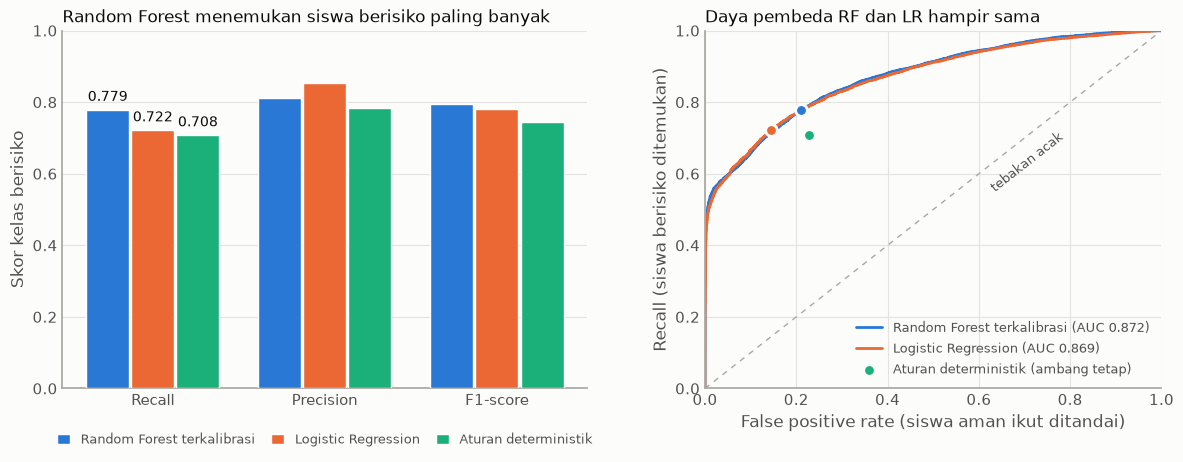

In [ ]:
WARNA = {'Random Forest terkalibrasi': '#2a78d6', 'Logistic Regression': '#eb6834', 'Aturan deterministik': '#1baf7a'}
TEKS, TEKS_2, GRID, LATAR = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

fig, (ax_bar, ax_roc) = plt.subplots(1, 2, figsize=(12, 4.8), facecolor=LATAR, gridspec_kw={'width_ratios': [1.15, 1]})

# Kiri: metrik pada ambang 0,50. Hanya recall yang diberi angka karena itu metrik penentu.
metrik = ['Recall berisiko', 'Precision berisiko', 'F1 berisiko']
lebar = 0.25
for i, (nama, warna) in enumerate(WARNA.items()):
    posisi = np.arange(len(metrik)) + (i - 1) * (lebar + 0.012)
    nilai = perbandingan.loc[nama, metrik].values
    ax_bar.bar(posisi, nilai, width=lebar, color=warna, label=nama, zorder=3)
    ax_bar.text(posisi[0], nilai[0] + 0.015, f'{nilai[0]:.3f}', ha='center', va='bottom', fontsize=10, color=TEKS)
ax_bar.set_xticks(np.arange(len(metrik)), ['Recall', 'Precision', 'F1-score'], color=TEKS, fontsize=11)
ax_bar.set_ylim(0, 1)
ax_bar.set_ylabel('Skor kelas berisiko', color=TEKS_2)
ax_bar.set_title('Random Forest menemukan siswa berisiko paling banyak', loc='left', color=TEKS, fontsize=12.5)
ax_bar.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False, fontsize=9.5, labelcolor=TEKS_2, handlelength=1, columnspacing=1.2)

# Kanan: kurva ROC. Titik menandai posisi tiap pendekatan pada ambang 0,50.
ax_roc.plot([0, 1], [0, 1], color='#a9a8a2', linewidth=1, linestyle=(0, (4, 4)), zorder=1)
ax_roc.text(0.62, 0.55, 'tebakan acak', color=TEKS_2, fontsize=9, rotation=38)
for nama, proba in {'Random Forest terkalibrasi': y_prob, 'Logistic Regression': y_prob_lr}.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax_roc.plot(fpr, tpr, color=WARNA[nama], linewidth=2, zorder=2, label=f'{nama} (AUC {skor_roc[nama]:.3f})')


def titik_kerja(pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return fp / (fp + tn), tp / (tp + fn)


for nama, pred in prediksi_biner.items():
    x, y = titik_kerja(pred)
    label = 'Aturan deterministik (ambang tetap)' if nama == 'Aturan deterministik' else None
    ax_roc.scatter(x, y, s=70, color=WARNA[nama], edgecolor=LATAR, linewidth=2, zorder=4, label=label)
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1)
ax_roc.set_xlabel('False positive rate (siswa aman ikut ditandai)', color=TEKS_2)
ax_roc.set_ylabel('Recall (siswa berisiko ditemukan)', color=TEKS_2)
ax_roc.set_title('Daya pembeda RF dan LR hampir sama', loc='left', color=TEKS, fontsize=12.5)
ax_roc.legend(loc='lower right', frameon=False, fontsize=9.5, labelcolor=TEKS_2)

for ax in (ax_bar, ax_roc):
    ax.set_facecolor(LATAR)
    ax.grid(True, color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(colors=TEKS_2, length=0)
    for sisi, garis in ax.spines.items():
        garis.set_visible(sisi in ('left', 'bottom'))
        garis.set_color('#a9a8a2')
ax_bar.grid(False, axis='x')
fig.tight_layout()
plt.show()

**Cara membaca.** Grafik kiri: dari setiap 100 siswa berisiko, Random Forest menemukan sekitar 78, Logistic Regression 72, dan aturan deterministik 71. Logistic Regression unggul pada precision (0,852 berbanding 0,812), artinya lebih sedikit siswa aman yang ikut ditandai.

Grafik kanan: kurva Random Forest dan Logistic Regression hampir berimpit (ROC-AUC 0,872 dan 0,869), jadi daya pembedanya hampir sama. Titik menandai posisi kerja pada ambang 0,50. Random Forest dipilih karena sistem ini mengutamakan siswa berisiko tidak terlewat (NFR-01), dan recall naik lagi menjadi 0,821 pada ambang 0,40 (bagian 7).

## 8. Bobot Fitur dan Ekspor Model
Menyimpan model terkalibrasi beserta metadata ke `ews_moodle_model.pkl`.

In [8]:
importances = np.mean([clf.estimator.feature_importances_ for clf in calibrated_model.calibrated_classifiers_], axis=0)
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

export_data = {
    'model': calibrated_model,
    'feature_cols': feature_cols,
    'threshold': OPTIMAL_THRESHOLD,
    'course_mapping': course_mapping.to_dict(orient='records')
}
joblib.dump(export_data, 'ews_moodle_model.pkl')
print("Model diekspor ke ews_moodle_model.pkl")
print("Top 5 fitur utama:")
print(feat_imp.head(5))

Model diekspor ke ews_moodle_model.pkl
Top 5 fitur utama:
missing_assignments      0.184688
score_rel_to_module      0.153712
days_inactive            0.105900
clicks_last_14d_ratio    0.078125
avg_score                0.077681
dtype: float64


## 9. Generator Payload JSON (Output API)
Fungsi inferensi menghasilkan payload data JSON terstruktur untuk backend API:
1. `generate_subject_teacher_payload()`: Endpoint data evaluasi per mata pelajaran untuk Guru Mapel.
2. `generate_bk_student_summary()`: Endpoint data agregasi rekapitulasi semester untuk Guru BK.

In [9]:
def generate_subject_teacher_payload(student_row, probability, threshold=0.40):
    """Menghasilkan payload JSON lengkap mencakup seluruh 24 fitur model (Tier 1)."""
    if probability >= 0.70:
        level_str = "TINGGI"
        urgency = "Perlu perhatian langsung dan konfirmasi tugas di kelas."
    elif probability >= threshold:
        level_str = "SEDANG"
        urgency = "Disarankan pemantauan berkala dan pendampingan materi."
    else:
        level_str = "RENDAH"
        urgency = "Aktivitas belajar terpantau normal."

    triggers = []
    if student_row['missing_assignments'] > 0:
        triggers.append(f"{int(student_row['missing_assignments'])} tugas belum dikumpulkan.")
    if student_row['lesson_attempts_count'] == 0 and student_row['total_cma_due'] > 0:
        triggers.append("Belum mengakses aktivitas Lesson interaktif.")
    elif student_row['lesson_avg_score'] < 50 and student_row['lesson_attempts_count'] > 0:
        triggers.append(f"Nilai rata-rata Lesson di bawah standar ({student_row['lesson_avg_score']:.1f}).")
    if student_row['course_duration_hours'] < 5.0:
        triggers.append(f"Akumulasi waktu belajar rendah ({student_row['course_duration_hours']:.1f} jam).")
    if student_row['days_inactive'] >= 7:
        triggers.append(f"Inaktif di kursus selama {int(student_row['days_inactive'])} hari.")
    if student_row['late_submission_count'] > 0:
        triggers.append(f"{int(student_row['late_submission_count'])} kali mengumpulkan tugas terlambat.")

    if not triggers:
        triggers.append("Aktivitas belajar menunjukkan kecenderungan penurunan.")

    return {
        "target_audience": "GURU_MATA_PELAJARAN",
        "id_siswa": int(student_row['id_student']),
        "mata_pelajaran": {
            "kode_modul": student_row['code_module'],
            "nama_mapel": student_row.get('nama_mapel', student_row['code_module']),
            "kategori": student_row.get('kategori_mapel', 'Kejuruan'),
            "guru_pengampu": student_row.get('nama_guru_mapel', '-'),
            "kkm": int(student_row.get('kkm', 70))
        },
        "analisis_risiko": {
            "tingkat_risiko": level_str,
            "probabilitas_risiko": round(float(probability), 3),
            "threshold": threshold
        },
        "metrik_24_fitur_model": {
            "engagement_dan_durasi": {
                "total_clicks": int(student_row['total_clicks']),
                "active_days": int(student_row['active_days']),
                "days_inactive": int(student_row['days_inactive']),
                "is_inactive_gt_5d": int(student_row['is_inactive_gt_5d']),
                "is_inactive_gt_14d": int(student_row['is_inactive_gt_14d']),
                "clicks_per_active_day": round(float(student_row['clicks_per_active_day']), 2),
                "clicks_last_14d_ratio": round(float(student_row['clicks_last_14d_ratio']), 3),
                "unique_sites_accessed": int(student_row['unique_sites_accessed']),
                "course_duration_hours": round(float(student_row['course_duration_hours']), 1)
            },
            "kepatuhan_tugas": {
                "missing_assignments": int(student_row['missing_assignments']),
                "late_submission_count": int(student_row['late_submission_count']),
                "avg_submission_gap": round(float(student_row['avg_submission_gap']), 1),
                "procrastination_count": int(student_row['procrastination_count'])
            },
            "aktivitas_lesson": {
                "lesson_attempts_count": int(student_row['lesson_attempts_count']),
                "lesson_time_spent_min": round(float(student_row['lesson_time_spent_min']), 1),
                "lesson_completion_ratio": round(float(student_row['lesson_completion_ratio']), 2),
                "lesson_avg_score": round(float(student_row['lesson_avg_score']), 1)
            },
            "akademik": {
                "avg_score": round(float(student_row['avg_score']), 1),
                "min_score": round(float(student_row['min_score']), 1),
                "score_rel_to_module": round(float(student_row['score_rel_to_module']), 1),
                "failing_tasks_count": int(student_row['failing_tasks_count']),
                "grade_trend": round(float(student_row['grade_trend']), 1)
            },
            "konteks_siswa": {
                "num_of_prev_attempts": int(student_row['num_of_prev_attempts']),
                "studied_credits": int(student_row['studied_credits'])
            }
        },
        "faktor_pemicu": triggers,
        "rekomendasi_tindakan": urgency
    }


def generate_bk_student_summary(student_id, df_all_records, model, feature_cols, threshold=0.40):
    """Menghasilkan payload JSON murni untuk Guru Bimbingan Konseling (Tier 2)."""
    records = df_all_records[df_all_records['id_student'] == student_id].copy()
    if records.empty:
        return {"error": f"Siswa ID {student_id} tidak ditemukan."}

    probs = model.predict_proba(records[feature_cols])[:, 1]
    records['prob'] = probs
    records['is_alert'] = records['prob'] >= threshold

    total_courses = len(records)
    at_risk_courses = records[records['is_alert']]
    at_risk_count = len(at_risk_courses)

    total_missing = records['missing_assignments'].sum()
    total_late = records['late_submission_count'].sum()
    total_hours = records['course_duration_hours'].sum()
    max_inactivity = records['days_inactive'].max()

    if at_risk_count >= 2:
        if total_missing >= 3 and total_late >= 2:
            character_profile = "Prokrastinasi Sistemik (Keterlambatan dan kelalaian tugas di banyak mapel)."
        elif max_inactivity >= 14:
            character_profile = "Inaktivitas Menyeluruh (Absensi belajar berkepanjangan dari LMS)."
        else:
            character_profile = "Kendala Belajar Multimapel."
        counseling_priority = "TINGGI"
        counseling_action = "Jadwalkan konseling individual dan koordinasi dengan wali kelas."
    elif at_risk_count == 1:
        failed_course = at_risk_courses.iloc[0]
        character_profile = f"Kesulitan Spesifik Mata Pelajaran ({failed_course.get('nama_mapel', failed_course['code_module'])})."
        counseling_priority = "SEDANG"
        counseling_action = "Koordinasi dengan Guru Mata Pelajaran pengampu untuk evaluasi remedial."
    else:
        character_profile = "Aktivitas Belajar Terkendali."
        counseling_priority = "RENDAH"
        counseling_action = "Pantau berkala."

    details = []
    for _, row in records.iterrows():
        status = "MERAH" if row['prob'] >= 0.70 else ("KUNING" if row['prob'] >= threshold else "HIJAU")
        details.append({
            "kode_modul": row['code_module'],
            "nama_mapel": row.get('nama_mapel', row['code_module']),
            "kategori": row.get('kategori_mapel', 'Kejuruan'),
            "guru_pengampu": row.get('nama_guru_mapel', '-'),
            "probabilitas": round(float(row['prob']), 3),
            "status_risiko": status,
            "tugas_belum_dikumpul": int(row['missing_assignments']),
            "durasi_belajar_jam": round(float(row['course_duration_hours']), 1),
            "lesson_attempts": int(row['lesson_attempts_count']),
            "days_inactive": int(row['days_inactive']),
            "avg_score": round(float(row['avg_score']), 1)
        })

    return {
        "target_audience": "GURU_BK",
        "id_siswa": int(student_id),
        "rekapitulasi_semester": {
            "total_mapel_diambil": int(total_courses),
            "total_mapel_berisiko": int(at_risk_count),
            "total_jam_belajar": round(float(total_hours), 1),
            "total_tugas_belum_dikumpul": int(total_missing),
            "total_tugas_terlambat": int(total_late),
            "inaktivitas_terlama_hari": int(max_inactivity)
        },
        "profil_karakter_belajar": character_profile,
        "prioritas_konseling": counseling_priority,
        "rekomendasi_tindakan": counseling_action,
        "rincian_per_mata_pelajaran": details
    }

In [10]:
sample_risk_id = df_final.loc[test_mask & (df_final['is_at_risk'] == 1), 'id_student'].iloc[0]
sample_row = df_final[df_final['id_student'] == sample_risk_id].iloc[0]
sample_prob = calibrated_model.predict_proba(sample_row[feature_cols].values.reshape(1, -1))[0, 1]

# 1. Contoh JSON Output Tier 1 (Guru Mapel)
json_teacher = generate_subject_teacher_payload(sample_row, sample_prob, threshold=OPTIMAL_THRESHOLD)
print("=== JSON PAYLOAD: TIER 1 (GURU MATA PELAJARAN) ===")
print(json.dumps(json_teacher, indent=2, ensure_ascii=False))

# 2. Contoh JSON Output Tier 2 (Guru BK)
json_bk = generate_bk_student_summary(sample_risk_id, df_final[test_mask], calibrated_model, feature_cols, threshold=OPTIMAL_THRESHOLD)
print("\n=== JSON PAYLOAD: TIER 2 (GURU BIMBINGAN KONSELING) ===")
print(json.dumps(json_bk, indent=2, ensure_ascii=False))

c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warni

=== JSON PAYLOAD: TIER 1 (GURU MATA PELAJARAN) ===
{
  "target_audience": "GURU_MATA_PELAJARAN",
  "id_siswa": 65002,
  "mata_pelajaran": {
    "kode_modul": "AAA",
    "nama_mapel": "Pemrograman Web dan Perangkat Bergerak",
    "kategori": "Kejuruan/Produktif",
    "guru_pengampu": "I Wayan Sudarma S.Kom.",
    "kkm": 75
  },
  "analisis_risiko": {
    "tingkat_risiko": "SEDANG",
    "probabilitas_risiko": 0.543,
    "threshold": 0.4
  },
  "metrik_24_fitur_model": {
    "engagement_dan_durasi": {
      "total_clicks": 170,
      "active_days": 10,
      "days_inactive": 9,
      "is_inactive_gt_5d": 1,
      "is_inactive_gt_14d": 0,
      "clicks_per_active_day": 17.0,
      "clicks_last_14d_ratio": 0.318,
      "unique_sites_accessed": 25,
      "course_duration_hours": 4.2
    },
    "kepatuhan_tugas": {
      "missing_assignments": 0,
      "late_submission_count": 0,
      "avg_submission_gap": -2.5,
      "procrastination_count": 0
    },
    "aktivitas_lesson": {
      "lesson_